# 数学文档是否比 general 更能降低目标 SFT loss？

从相同 reference 模型出发，分别用 General FineWeb、OpenWebMath、OpenStax 和 FineMath-4+
做文档继续训练，随后在同一套留出 MATH 问答上计算回答 NLL。没有再训练 target SFT。
**loss 下降量与相对下降比例并列考察，不设主次。** 本轮指标是实际目标 loss 的变化，使用来源识别 AUC 的旧结果不等于训练效用。

In [1]:
from pathlib import Path
import json,hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
root=Path.cwd();snap=root/'snapshot';manifest=json.loads((root/'manifest.json').read_text())
for name,info in manifest['files'].items():assert hashlib.sha256((snap/name).read_bytes()).hexdigest()==info['sha256'],name
metrics=json.loads((snap/'metrics.json').read_text())
data=pd.read_parquet(snap/'per_example.parquet');training=pd.read_parquet(snap/'training.parquet')
names={'general':'General FineWeb','openwebmath':'OpenWebMath','openstax':'OpenStax','finemath':'FineMath-4+'}
arms=list(names);seeds=metrics['seeds'];keys=['delta_loss','relative_gain'];ref=metrics['reference_mean_nll']
colors={'general':'#777777','openwebmath':'#2379B5','openstax':'#31935F','finemath':'#D8792E'}
def ci(x):return f'[{x[0]:.5f}, {x[1]:.5f}]'
print('Reference held-out mean answer NLL:',ref)
print('目标样本 / 问题组：',metrics['target_examples'],metrics['target_groups'])

Reference held-out mean answer NLL: 0.7434983319690218
目标样本 / 问题组： 512 512


## 固定训练预算与实验单位

四种来源 × seed 42/43/44，共 12 个 run。各 64 步，每步 16,384 个有效预测 token，
合计 1,048,576 个；学习率 2e-5、warmup 7 步、线性衰减，AdamW 设置一致。
不放回打乱已有文档窗口，分步边界保留窗口前缀作为上下文并 mask 已消费目标；无跨文档拼接。
不同 seed 同时改变窗口抽样和顺序。按 token 配平，样本数和输入上下文量可以不同。

FP32 master/optimizer、bf16 autocast、SDPA math；保持有限梯度检查。固定 step 64 评估，
step 32 只用于完整状态保存/恢复。General seed 42 实际从 step 32 恢复。
目标为原 512 条留出 MATH，完整 FP32 评分、同 tokens/response mask，未用于选模型。
General 是原未标注背景，不能等同于人工确认的非数学语料。

,arm,seed,documents,fragments,supervised_tokens,input_tokens,steps
0,general,42,1507,1610,1048576,1083894,64
1,general,43,1632,1719,1048576,1080387,64
2,general,44,1529,1619,1048576,1088483,64
3,openwebmath,42,483,818,1048576,1108117,64
4,openwebmath,43,527,848,1048576,1116930,64
5,openwebmath,44,513,834,1048576,1100373,64
6,openstax,42,115,623,1048576,1110046,64
7,openstax,43,112,626,1048576,1112520,64
8,openstax,44,115,630,1048576,1109348,64
9,finemath,42,795,1041,1048576,1100723,64


,arm,seed,observed steps,tokens,finite gradients
0,finemath,42,64,1048576,True
1,finemath,43,64,1048576,True
2,finemath,44,64,1048576,True
3,general,42,64,1048576,True
4,general,43,64,1048576,True
5,general,44,64,1048576,True
6,openstax,42,64,1048576,True
7,openstax,43,64,1048576,True
8,openstax,44,64,1048576,True
9,openwebmath,42,64,1048576,True


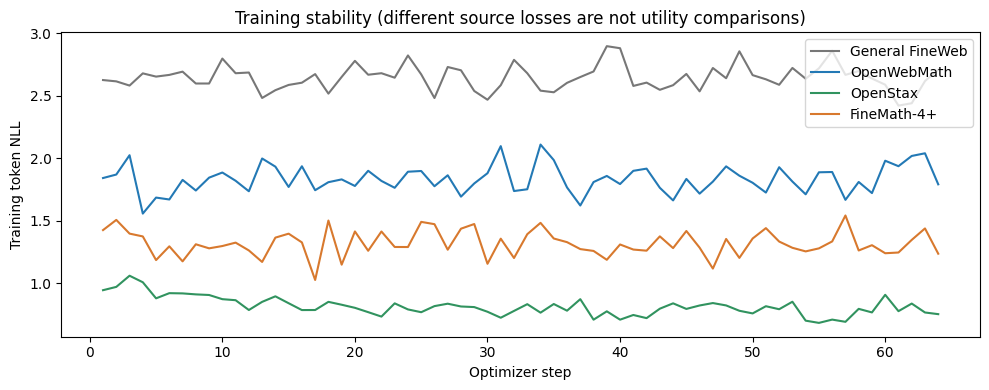

In [2]:
recipes=pd.DataFrame(metrics['data_preparation']['runs'])
display(recipes[['arm','seed','documents','fragments','supervised_tokens','input_tokens','steps']])
assert recipes.supervised_tokens.nunique()==1 and recipes.supervised_tokens.iloc[0]==1048576
display(pd.DataFrame([{'arm':a,'seed':s,'observed steps':len(g),'tokens':g.response_tokens.sum(),
    'finite gradients':np.isfinite(g.grad_norm).all()} for (a,s),g in training.groupby(['arm','seed'])]))
fig,ax=plt.subplots(figsize=(10,4))
for arm in arms:
    g=training.loc[training.arm==arm].groupby('step').loss.mean()
    ax.plot(g.index,g,label=names[arm],color=colors[arm])
ax.set(xlabel='Optimizer step',ylabel='Training token NLL',title='Training stability (different source losses are not utility comparisons)');ax.legend()
fig.tight_layout();plt.show();plt.close(fig)

## 留出 MATH 回答 loss：全部种子与绝对改善

,source,seed,target NLL,delta_loss,relative_gain
0,General FineWeb,42,0.712004,0.031494,0.038656
1,General FineWeb,43,0.712760,0.030739,0.037077
2,General FineWeb,44,0.720355,0.023144,0.027503
3,OpenWebMath,42,0.711411,0.032087,0.036371
4,OpenWebMath,43,0.712411,0.031087,0.035362
5,OpenWebMath,44,0.705310,0.038189,0.046788
6,OpenStax,42,0.878771,-0.135273,-0.253347
7,OpenStax,43,0.903366,-0.159868,-0.293052
8,OpenStax,44,0.893638,-0.150139,-0.274763
9,FineMath-4+,42,0.724000,0.019499,0.018393


,source,mean target NLL,delta_loss,relative_gain
0,General FineWeb,0.715040,0.028459,0.034412
1,OpenWebMath,0.709711,0.033788,0.039507
2,OpenStax,0.891925,-0.148427,-0.273721
3,FineMath-4+,0.721796,0.021703,0.022058


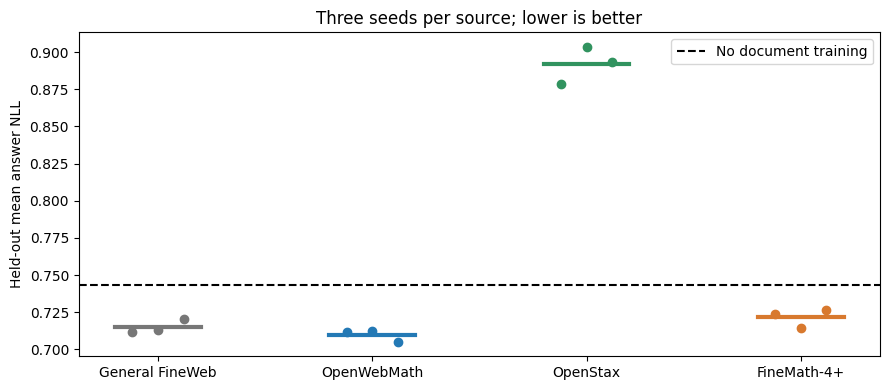

In [3]:
per_seed=[];summary=[]
for arm,result in metrics['arms'].items():
    for i,seed in enumerate(seeds):
        per_seed.append({'source':names[arm],'seed':seed,'target NLL':result['per_seed_target_nll'][i],
            **{k:result['scores'][k]['per_seed'][i] for k in keys}})
    summary.append({'source':names[arm],'mean target NLL':result['mean_target_nll'],
        **{k:result['scores'][k]['mean'] for k in keys}})
display(pd.DataFrame(per_seed).round(6));display(pd.DataFrame(summary).round(6))
fig,ax=plt.subplots(figsize=(9,4))
for i,arm in enumerate(arms):
    r=metrics['arms'][arm];ax.scatter([i-.12,i,i+.12],r['per_seed_target_nll'],color=colors[arm])
    ax.plot([i-.2,i+.2],[r['mean_target_nll']]*2,color=colors[arm],linewidth=3)
ax.axhline(ref,color='black',linestyle='--',label='No document training')
ax.set(xticks=range(4),xticklabels=[names[a] for a in arms],ylabel='Held-out mean answer NLL',title='Three seeds per source; lower is better');ax.legend()
fig.tight_layout();plt.show();plt.close(fig)

## 数学来源相对 general 的配对效用

对同一个 seed、同一个问题计算 `gain_math − gain_general`，正值表示数学源更有利。
下降量差也等于 `L_general − L_math`。绝对 gain 为负表示损失增加，不能把“增加较少”当作“下降”。

表中给出两套 95% 区间：conditional 仅重采样问题组，条件于三个训练模型；hierarchical 同时重采样
seed 与问题组，并在来源之间共享索引。只有三个 seed，训练随机性的总体不确定性仍只能粗略估计。

,source,metric,mean advantage over general,seed 42,seed 43,seed 44,conditional 95% CI,hierarchical 95% CI
0,OpenWebMath,delta_loss,0.005329,0.000593,0.000349,0.015045,"[0.00382, 0.00688]","[-0.00059, 0.01468]"
1,OpenWebMath,relative_gain,0.005094,-0.002285,-0.001715,0.019284,"[0.00292, 0.00736]","[-0.00359, 0.01883]"
2,OpenStax,delta_loss,-0.176885,-0.166767,-0.190607,-0.173283,"[-0.18633, -0.16810]","[-0.19191, -0.16349]"
3,OpenStax,relative_gain,-0.308133,-0.292003,-0.330129,-0.302267,"[-0.32965, -0.28565]","[-0.33736, -0.28095]"
4,FineMath-4+,delta_loss,-0.006756,-0.011995,-0.001926,-0.006347,"[-0.00839, -0.00506]","[-0.01191, -0.00211]"
5,FineMath-4+,relative_gain,-0.012355,-0.020263,-0.004727,-0.012074,"[-0.01478, -0.00973]","[-0.02002, -0.00511]"


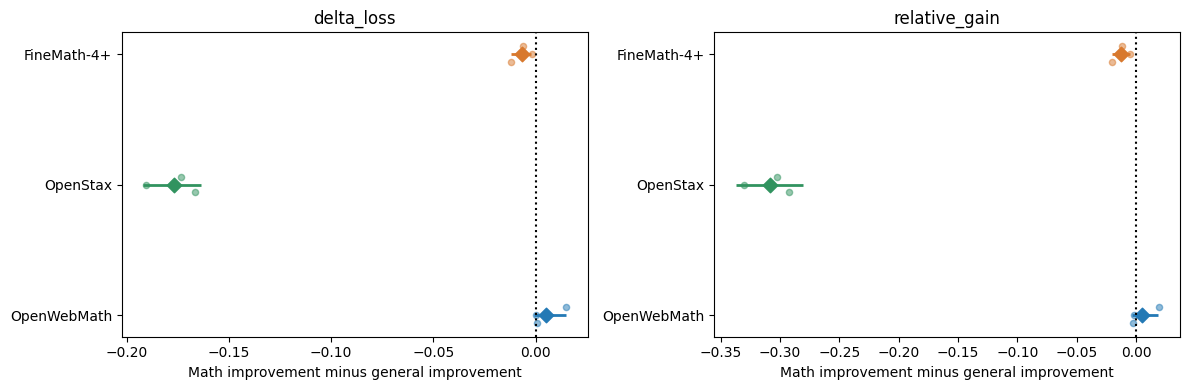

In [4]:
rows=[]
for arm in arms[1:]:
    for key in keys:
        v=metrics['arms'][arm]['contrast_vs_general'][key]
        rows.append({'source':names[arm],'metric':key,'mean advantage over general':v['mean'],
            **{f'seed {s}':v['per_seed'][i] for i,s in enumerate(seeds)},
            'conditional 95% CI':ci(v['conditional_ci95']),'hierarchical 95% CI':ci(v['hierarchical_ci95'])})
display(pd.DataFrame(rows).round(6))
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,key in zip(axes,keys):
    for i,arm in enumerate(arms[1:]):
        v=metrics['arms'][arm]['contrast_vs_general'][key]
        ax.hlines(i,*v['hierarchical_ci95'],color=colors[arm],linewidth=2)
        ax.scatter(v['per_seed'],[i-.06,i,i+.06],color=colors[arm],alpha=.5,s=20)
        ax.scatter([v['mean']],[i],color=colors[arm],s=55,marker='D')
    ax.axvline(0,color='black',linestyle=':')
    ax.set(yticks=range(3),yticklabels=[names[a] for a in arms[1:]],xlabel='Math improvement minus general improvement',title=key)
fig.tight_layout();plt.show();plt.close(fig)

## 同一批目标问题上的配对结果

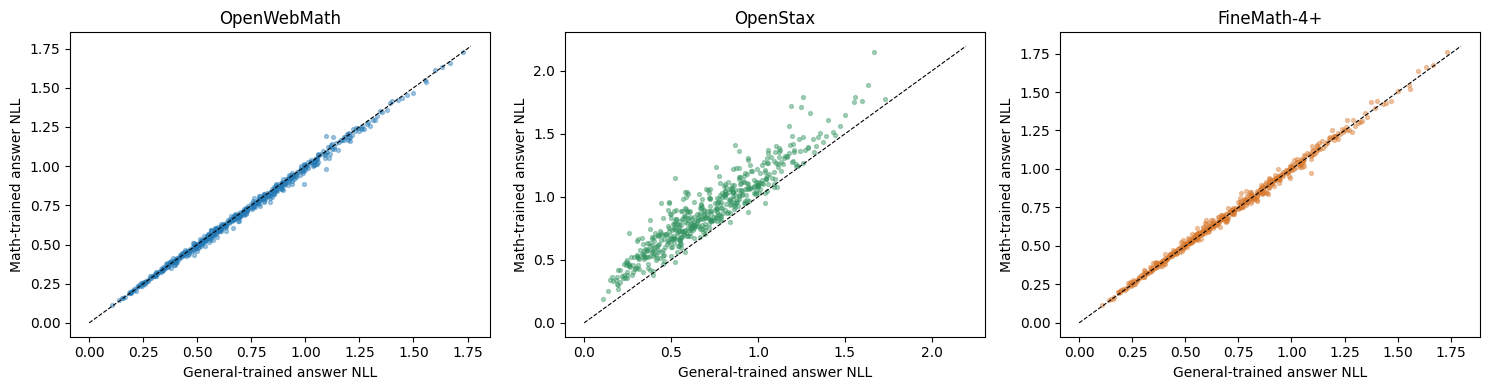

每个点为同一道留出题在三个 seed 上的平均 NLL；对角线下方表示数学来源更有利。


In [5]:
avg=data.groupby(['arm','id']).trained_mean_nll.mean().unstack('arm')
fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,arm in zip(axes,arms[1:]):
    ax.scatter(avg.general,avg[arm],s=8,alpha=.4,color=colors[arm]);bound=avg[['general',arm]].to_numpy().max()*1.02
    ax.plot([0,bound],[0,bound],'k--',linewidth=.8)
    ax.set(xlabel='General-trained answer NLL',ylabel='Math-trained answer NLL',title=names[arm])
fig.tight_layout();plt.show();plt.close(fig)
print('每个点为同一道留出题在三个 seed 上的平均 NLL；对角线下方表示数学来源更有利。')

## 校验与解释边界

In [6]:
assert len(data)==12*512
for arm,result in metrics['arms'].items():
    f=data.loc[data.arm==arm]
    for i,seed in enumerate(seeds):
        g=f.loc[f.seed==seed];assert g.id.is_unique and len(g)==512
        np.testing.assert_allclose(g.trained_mean_nll.mean(),result['per_seed_target_nll'][i],atol=1e-12,rtol=0)
        for key in keys:np.testing.assert_allclose(g[key].mean(),result['scores'][key]['per_seed'][i],atol=1e-12,rtol=0)
print('Reference 交叉复核最大 NLL 差：',metrics['reference_crosscheck_max_nll_difference'])
print('真实 resume 验证：',metrics['actual_resume'])
for arm in arms[1:]:
    for key in keys:
        v=metrics['arms'][arm]['contrast_vs_general'][key];lo,hi=v['hierarchical_ci95']
        meaning='数学来源更有利' if lo>0 else '数学来源更不利' if hi<0 else '区间覆盖零，尚无明确方向'
        display(Markdown(f"**{names[arm]} / {key}**：相对 general 的改善差 **{v['mean']:.6f}**，hierarchical 95% CI {ci(v['hierarchical_ci95'])}；{meaning}。"))

Reference 交叉复核最大 NLL 差： 4.76837158203125e-06
真实 resume 验证： {'checkpoint': '/mnt/tianzhu_hot/data-picking/runs/document-utility-qwen25-1p5b-t1048576-s64-general-seed42/checkpoints/step-000032-92307a09', 'step': 32, 'optimizer_steps': [32], 'scheduler_step': 32, 'rng_restored': True, 'data_orders_and_batches_restored': True, 'seen_response_tokens': 524288}


**OpenWebMath / delta_loss**：相对 general 的改善差 **0.005329**，hierarchical 95% CI [-0.00059, 0.01468]；区间覆盖零，尚无明确方向。

**OpenWebMath / relative_gain**：相对 general 的改善差 **0.005094**，hierarchical 95% CI [-0.00359, 0.01883]；区间覆盖零，尚无明确方向。

**OpenStax / delta_loss**：相对 general 的改善差 **-0.176885**，hierarchical 95% CI [-0.19191, -0.16349]；数学来源更不利。

**OpenStax / relative_gain**：相对 general 的改善差 **-0.308133**，hierarchical 95% CI [-0.33736, -0.28095]；数学来源更不利。

**FineMath-4+ / delta_loss**：相对 general 的改善差 **-0.006756**，hierarchical 95% CI [-0.01191, -0.00211]；数学来源更不利。

**FineMath-4+ / relative_gain**：相对 general 的改善差 **-0.012355**，hierarchical 95% CI [-0.02002, -0.00511]；数学来源更不利。

这些结论只对应本轮 reference 模型、语料池、训练预算与优化设置。
“没有检出数学来源优势”不能证明两者等价；即使结果与先前 loss 变化的方向一致，也只是来源层面的证据。
本轮没有在同一候选池内比较按分数挑选和随机挑选，因此没有证明逐样本数据排序的准确性。
检查点 I/O 的修订不改变数值训练代码；完整状态、有效 token 数和原始日志均保留。